In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [ ]:
import os
import pandas as pd

df = pd.read_excel('/content/LOAN PREDICTION DATASET.xlsx')

In [ ]:
df.head()

,Age,Gender,Education,Person Income,Employee Experience,Home Onwership,Loan Amount,Loan Intent,Loan interest Rate,Loan percentage,Credit History,Credit Score,Previous Loan,Loan Status
0,22,female,Master,71948,0,RENT,35000,PERSONAL,16.02,0.49,3,561,No,1
1,21,female,High School,12282,0,OWN,1000,EDUCATION,11.14,0.08,2,504,Yes,0
2,25,female,High School,12438,3,MORTGAGE,5500,MEDICAL,12.87,0.44,3,635,No,1
3,23,female,Bachelor,79753,0,RENT,35000,MEDICAL,15.23,0.44,2,675,No,1
4,24,male,Master,66135,1,RENT,35000,MEDICAL,14.27,0.53,4,586,No,1


In [ ]:
df.tail()

,Age,Gender,Education,Person Income,Employee Experience,Home Onwership,Loan Amount,Loan Intent,Loan interest Rate,Loan percentage,Credit History,Credit Score,Previous Loan,Loan Status
44995,27,male,Associate,47971,6,RENT,15000,MEDICAL,15.66,0.31,3,645,No,1
44996,37,female,Associate,65800,17,RENT,9000,HOMEIMPROVEMENT,14.07,0.14,11,621,No,1
44997,33,male,Associate,56942,7,RENT,2771,DEBTCONSOLIDATION,10.02,0.05,10,668,No,1
44998,29,male,Bachelor,33164,4,RENT,12000,EDUCATION,13.23,0.36,6,604,No,1
44999,24,male,High School,51609,1,RENT,6665,DEBTCONSOLIDATION,17.05,0.13,3,628,No,1


In [ ]:
#TASK 2  UNDERSTAND THE DATASET
# 1. Number of rows
df.shape   # shows that  45000 rows and  14 colms

(45000, 14)

In [ ]:
df.columns

Index(['Age', 'Gender', 'Education', 'Person Income', 'Employee Experience',
       'Home Onwership', 'Loan Amount', 'Loan Intent', 'Loan interest Rate',
       'Loan percentage', 'Credit History', 'Credit Score', 'Previous Loan',
       'Loan Status'],
      dtype='object')

In [ ]:
df.dtypes

,0
Age,int64
Gender,object
Education,object
Person Income,int64
Employee Experience,int64
Home Onwership,object
Loan Amount,int64
Loan Intent,object
Loan interest Rate,float64
Loan percentage,float64


In [ ]:
df.describe()

,Age,Person Income,Employee Experience,Loan Amount,Loan interest Rate,Loan percentage,Credit History,Credit Score,Loan Status
count,45000.000000,4.500000e+04,45000.000000,45000.000000,45000.000000,45000.000000,45000.000000,45000.000000,45000.000000
mean,27.764178,8.031905e+04,5.410333,9583.157556,11.006606,0.139725,5.867489,632.608756,0.222222
std,6.045108,8.042250e+04,6.063532,6314.886691,2.978808,0.087212,3.879702,50.435865,0.415744
min,20.000000,8.000000e+03,0.000000,500.000000,5.420000,0.000000,2.000000,390.000000,0.000000
25%,24.000000,4.720400e+04,1.000000,5000.000000,8.590000,0.070000,3.000000,601.000000,0.000000
50%,26.000000,6.704800e+04,4.000000,8000.000000,11.010000,0.120000,4.000000,640.000000,0.000000
75%,30.000000,9.578925e+04,8.000000,12237.250000,12.990000,0.190000,8.000000,670.000000,0.000000
max,144.000000,7.200766e+06,125.000000,35000.000000,20.000000,0.660000,30.000000,850.000000,1.000000


In [ ]:
#Statistical Summary of categorical colms
df.describe(include='object')   #The parameter include='object' tells Pandas to summarize only the categorical (object/string) columns.

,Gender,Education,Home Onwership,Loan Intent,Previous Loan
count,45000,45000,45000,45000,45000
unique,2,5,4,6,2
top,male,Bachelor,RENT,EDUCATION,Yes
freq,24841,13399,23443,9153,22858


In [ ]:
# TASK 3 IDENTIFY MISSING VALUES
# missing values
# Display the number of missing values in each column
df.isnull().sum()

,0
Age,0
Gender,0
Education,0
Person Income,0
Employee Experience,0
Home Onwership,0
Loan Amount,0
Loan Intent,0
Loan interest Rate,0
Loan percentage,0


In [ ]:
## CHECK DuPLICATES RECORDS
# Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Remove duplicates
df = df.drop_duplicates()

Duplicate rows: 0


In [ ]:
####### target vriable
# what is the target variable?
#The target variable is Loan status.
#It represents whether a loan application was approved or rejected.

In [ ]:
df['Loan Status'].value_counts()

,count
Loan Status,
0,35000
1,10000


In [ ]:
df['Previous Loan'].value_counts()

,count
Previous Loan,
Yes,22858
No,22142


In [ ]:
df['Loan Status'].value_counts(normalize=True) * 100

,proportion
Loan Status,
0,77.777778
1,22.222222


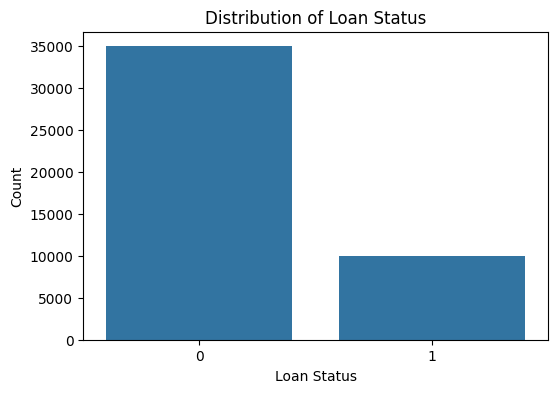

In [ ]:
## plot to visualize the target variable
plt.figure(figsize=(6,4))
sns.countplot(x='Loan Status', data=df)
plt.title("Distribution of Loan Status")
plt.xlabel("Loan Status")
plt.ylabel("Count")
plt.show()

In [ ]:
df['Home Onwership'].value_counts()

,count
Home Onwership,
RENT,23443
MORTGAGE,18489
OWN,2951
OTHER,117


In [ ]:
df['Loan Intent'].value_counts()

,count
Loan Intent,
EDUCATION,9153
MEDICAL,8548
VENTURE,7819
PERSONAL,7552
DEBTCONSOLIDATION,7145
HOMEIMPROVEMENT,4783


In [ ]:
df['Gender'].value_counts()

,count
Gender,
male,24841
female,20159


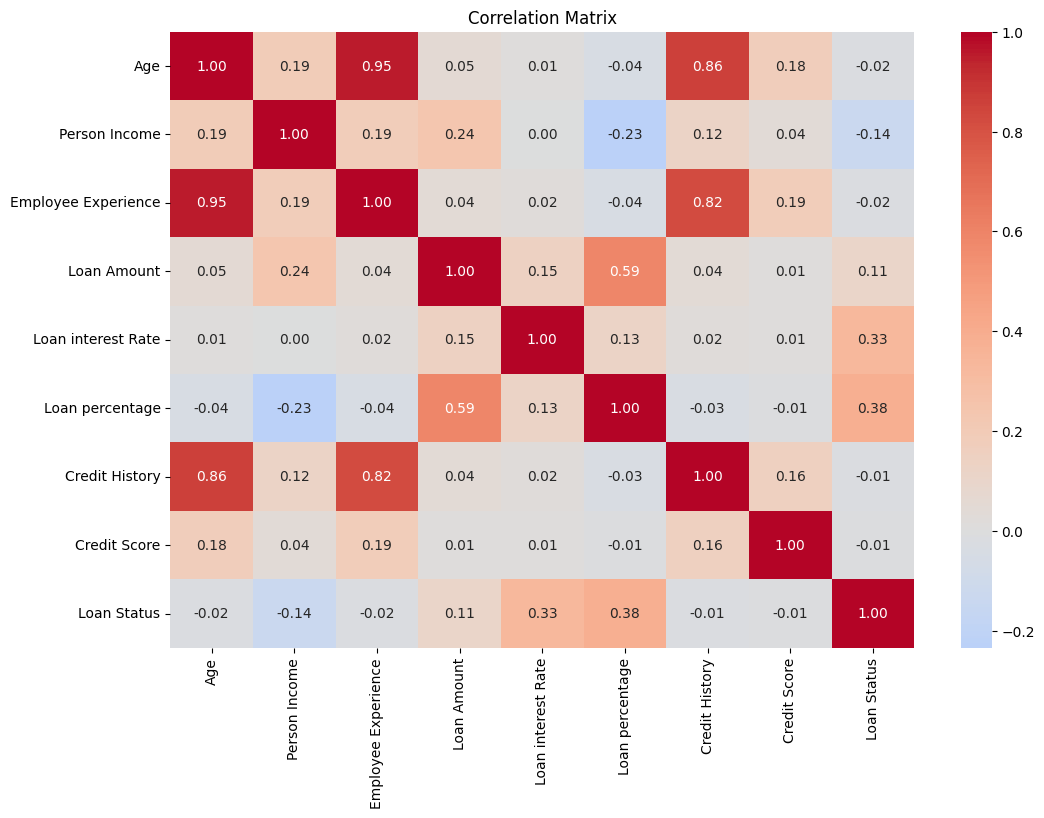

In [ ]:
# Select numerical variables
numeric_df = df.select_dtypes(include=np.number)

# Correlation matrix
corr_matrix = numeric_df.corr()

# Heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    center=0
)

plt.title('Correlation Matrix')
plt.show()

In [ ]:
df = df.drop(columns=['Gender', 'Education', 'Previous Loan'])

In [ ]:
df

,Age,Person Income,Employee Experience,Home Onwership,Loan Amount,Loan Intent,Loan interest Rate,Loan percentage,Credit History,Credit Score,Loan Status
0,22,71948,0,RENT,35000,PERSONAL,16.02,0.49,3,561,1
1,21,12282,0,OWN,1000,EDUCATION,11.14,0.08,2,504,0
2,25,12438,3,MORTGAGE,5500,MEDICAL,12.87,0.44,3,635,1
3,23,79753,0,RENT,35000,MEDICAL,15.23,0.44,2,675,1
4,24,66135,1,RENT,35000,MEDICAL,14.27,0.53,4,586,1
...,...,...,...,...,...,...,...,...,...,...,...
44995,27,47971,6,RENT,15000,MEDICAL,15.66,0.31,3,645,1
44996,37,65800,17,RENT,9000,HOMEIMPROVEMENT,14.07,0.14,11,621,1
44997,33,56942,7,RENT,2771,DEBTCONSOLIDATION,10.02,0.05,10,668,1
44998,29,33164,4,RENT,12000,EDUCATION,13.23,0.36,6,604,1


In [ ]:
#encode categorical variable
# Check data types
print(df.dtypes)

# Display categorical columns
categorical_cols = df.select_dtypes(include=['object', 'category']).columns
print("Categorical variables:")
print(categorical_cols)

Age                      int64
Person Income            int64
Employee Experience      int64
Home Onwership          object
Loan Amount              int64
Loan Intent             object
Loan interest Rate     float64
Loan percentage        float64
Credit History           int64
Credit Score             int64
Loan Status              int64
dtype: object
Categorical variables:
Index(['Home Onwership', 'Loan Intent'], dtype='object')


In [ ]:
from sklearn.preprocessing import LabelEncoder

# Find categorical columns
categorical_cols = df.select_dtypes(include=['object', 'category']).columns

# Create LabelEncoder
le = LabelEncoder()

# Encode each categorical variable
for col in categorical_cols:
    df[col] = le.fit_transform(df[col].astype(str))



In [ ]:
df.head()

,Age,Person Income,Employee Experience,Home Onwership,Loan Amount,Loan Intent,Loan interest Rate,Loan percentage,Credit History,Credit Score,Loan Status
0,22,71948,0,3,35000,4,16.02,0.49,3,561,1
1,21,12282,0,2,1000,1,11.14,0.08,2,504,0
2,25,12438,3,0,5500,3,12.87,0.44,3,635,1
3,23,79753,0,3,35000,3,15.23,0.44,2,675,1
4,24,66135,1,3,35000,3,14.27,0.53,4,586,1


In [ ]:
#### TRAIN TEST SPLIT
from sklearn.model_selection import train_test_split

# Independent variables
X = df.drop('Loan Status', axis=1)

# Dependent/target variable
y = df['Loan Status']

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (45000, 10)
y shape: (45000,)


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (36000, 10)
Testing data: (9000, 10)


In [ ]:
print("Original target distribution:")
print(y.value_counts())

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Original target distribution:
Loan Status
0    35000
1    10000
Name: count, dtype: int64

Training target distribution:
Loan Status
0    28000
1     8000
Name: count, dtype: int64

Testing target distribution:
Loan Status
0    7000
1    2000
Name: count, dtype: int64


In [ ]:
print("Training target percentage:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting target percentage:")
print(y_test.value_counts(normalize=True) * 100)

Training target percentage:
Loan Status
0    77.777778
1    22.222222
Name: proportion, dtype: float64

Testing target percentage:
Loan Status
0    77.777778
1    22.222222
Name: proportion, dtype: float64


the target proportions to make sure the train and test datasets have a similar distribution of the two classes.

In [ ]:
## SMOTE ANALYSIS
!pip install imbalanced-learn
from imblearn.over_sampling import SMOTE


In [ ]:
print("Before SMOTE:")
print(y_train.value_counts())

Before SMOTE:
Loan Status
0    28000
1     8000
Name: count, dtype: int64


In [ ]:
smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

In [ ]:
print("After SMOTE:")
print(y_train_smote.value_counts())

After SMOTE:
Loan Status
0    28000
1    28000
Name: count, dtype: int64


In [ ]:
print("After SMOTE - Percentage:")
print(y_train_smote.value_counts(normalize=True) * 100)

After SMOTE - Percentage:
Loan Status
0    50.0
1    50.0
Name: proportion, dtype: float64


In [ ]:
print("Before SMOTE:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nAfter SMOTE:")
print("X_train_smote:", X_train_smote.shape)
print("y_train_smote:", y_train_smote.shape)

print("\nTest data:")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)


Before SMOTE:
X_train: (36000, 10)
y_train: (36000,)

After SMOTE:
X_train_smote: (56000, 10)
y_train_smote: (56000,)

Test data:
X_test: (9000, 10)
y_test: (9000,)


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Fit only on SMOTE training data
X_train_scaled = scaler.fit_transform(X_train_smote)

# Transform test data using the same scaler
X_test_scaled = scaler.transform(X_test)

print("Scaled training data:", X_train_scaled.shape)
print("Scaled test data:", X_test_scaled.shape)

Scaled training data: (56000, 10)
Scaled test data: (9000, 10)


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

lr = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr.fit(X_train_scaled, y_train_smote)

lr_train_pred = lr.predict(X_train_scaled)
lr_test_pred = lr.predict(X_test_scaled)

lr_train_acc = accuracy_score(y_train_smote, lr_train_pred)
lr_test_acc = accuracy_score(y_test, lr_test_pred)

print("LOGISTIC REGRESSION")
print("Training Accuracy:", round(lr_train_acc, 4))
print("Testing Accuracy :", round(lr_test_acc, 4))
print("Overfitting Gap  :", round(lr_train_acc - lr_test_acc, 4))

LOGISTIC REGRESSION
Training Accuracy: 0.7755
Testing Accuracy : 0.7738
Overfitting Gap  : 0.0018


In [ ]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(
    max_depth=5,
    min_samples_split=20,
    min_samples_leaf=10,
    random_state=42
)

dt.fit(X_train_smote, y_train_smote)

dt_train_pred = dt.predict(X_train_smote)
dt_test_pred = dt.predict(X_test)

dt_train_acc = accuracy_score(y_train_smote, dt_train_pred)
dt_test_acc = accuracy_score(y_test, dt_test_pred)

print("DECISION TREE")
print("Training Accuracy:", round(dt_train_acc, 4))
print("Testing Accuracy :", round(dt_test_acc, 4))
print("Overfitting Gap  :", round(dt_train_acc - dt_test_acc, 4))

DECISION TREE
Training Accuracy: 0.8184
Testing Accuracy : 0.8622
Overfitting Gap  : -0.0438


In [ ]:
from sklearn.svm import SVC

svm = SVC(
    kernel='rbf',
    C=1.0,
    random_state=42
)

svm.fit(X_train_scaled, y_train_smote)

svm_train_pred = svm.predict(X_train_scaled)
svm_test_pred = svm.predict(X_test_scaled)

svm_train_acc = accuracy_score(y_train_smote, svm_train_pred)
svm_test_acc = accuracy_score(y_test, svm_test_pred)

print("SUPPORT VECTOR MACHINE")
print("Training Accuracy:", round(svm_train_acc, 4))
print("Testing Accuracy :", round(svm_test_acc, 4))
print("Overfitting Gap  :", round(svm_train_acc - svm_test_acc, 4))

SUPPORT VECTOR MACHINE
Training Accuracy: 0.8324
Testing Accuracy : 0.8238
Overfitting Gap  : 0.0087


In [ ]:
results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Decision Tree',
        'SVM'
    ],
    'Training Accuracy': [
        lr_train_acc,
        dt_train_acc,
        svm_train_acc
    ],
    'Testing Accuracy': [
        lr_test_acc,
        dt_test_acc,
        svm_test_acc
    ]
})

results['Overfitting Gap'] = (
    results['Training Accuracy'] -
    results['Testing Accuracy']
)

print(results)

                 Model  Training Accuracy  Testing Accuracy  Overfitting Gap
0  Logistic Regression           0.775536          0.773778         0.001758
1        Decision Tree           0.818411          0.862222        -0.043812
2                  SVM           0.832446          0.823778         0.008669


Class Weights — another way to handle imbalance

After SMOTE, class weights as an alternative imbalance-handling technique.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

# Scale original training data
scaler_weight = StandardScaler()

X_train_weighted = scaler_weight.fit_transform(X_train)
X_test_weighted = scaler_weight.transform(X_test)

# Weighted Logistic Regression
lr_weighted = LogisticRegression(
    class_weight='balanced',
    max_iter=1000,
    random_state=42
)

lr_weighted.fit(X_train_weighted, y_train)

# Predictions
lr_w_train_pred = lr_weighted.predict(X_train_weighted)
lr_w_test_pred = lr_weighted.predict(X_test_weighted)

print("WEIGHTED LOGISTIC REGRESSION")
print("Training Accuracy:",
      round(accuracy_score(y_train, lr_w_train_pred), 4))

print("Testing Accuracy:",
      round(accuracy_score(y_test, lr_w_test_pred), 4))

print("Overfitting Gap:",
      round(
          accuracy_score(y_train, lr_w_train_pred) -
          accuracy_score(y_test, lr_w_test_pred), 4
      ))

WEIGHTED LOGISTIC REGRESSION
Training Accuracy: 0.7668
Testing Accuracy: 0.7716
Overfitting Gap: -0.0048


In [ ]:
from sklearn.tree import DecisionTreeClassifier

dt_weighted = DecisionTreeClassifier(
    max_depth=5,
    min_samples_split=20,
    min_samples_leaf=10,
    class_weight='balanced',
    random_state=42
)

dt_weighted.fit(X_train, y_train)

# Predictions
dt_w_train_pred = dt_weighted.predict(X_train)
dt_w_test_pred = dt_weighted.predict(X_test)

print("WEIGHTED DECISION TREE")
print("Training Accuracy:",
      round(accuracy_score(y_train, dt_w_train_pred), 4))

print("Testing Accuracy:",
      round(accuracy_score(y_test, dt_w_test_pred), 4))

print("Overfitting Gap:",
      round(
          accuracy_score(y_train, dt_w_train_pred) -
          accuracy_score(y_test, dt_w_test_pred), 4
      ))

WEIGHTED DECISION TREE
Training Accuracy: 0.8785
Testing Accuracy: 0.8734
Overfitting Gap: 0.005


In [ ]:
from sklearn.svm import SVC

svm_weighted = SVC(
    kernel='rbf',
    C=1.0,
    class_weight='balanced',
    random_state=42
)

svm_weighted.fit(X_train_weighted, y_train)

# Predictions
svm_w_train_pred = svm_weighted.predict(X_train_weighted)
svm_w_test_pred = svm_weighted.predict(X_test_weighted)

print("WEIGHTED SVM")
print("Training Accuracy:",
      round(accuracy_score(y_train, svm_w_train_pred), 4))

print("Testing Accuracy:",
      round(accuracy_score(y_test, svm_w_test_pred), 4))

print("Overfitting Gap:",
      round(
          accuracy_score(y_train, svm_w_train_pred) -
          accuracy_score(y_test, svm_w_test_pred), 4
      ))

WEIGHTED SVM
Training Accuracy: 0.8353
Testing Accuracy: 0.8338
Overfitting Gap: 0.0016


In [ ]:
weighted_results = pd.DataFrame({
    'Model': [
        'Weighted Logistic Regression',
        'Weighted Decision Tree',
        'Weighted SVM'
    ],

    'Training Accuracy': [
        accuracy_score(y_train, lr_w_train_pred),
        accuracy_score(y_train, dt_w_train_pred),
        accuracy_score(y_train, svm_w_train_pred)
    ],

    'Testing Accuracy': [
        accuracy_score(y_test, lr_w_test_pred),
        accuracy_score(y_test, dt_w_test_pred),
        accuracy_score(y_test, svm_w_test_pred)
    ]
})

weighted_results['Overfitting Gap'] = (
    weighted_results['Training Accuracy'] -
    weighted_results['Testing Accuracy']
)

print(weighted_results.round(4))

                          Model  Training Accuracy  Testing Accuracy  \
0  Weighted Logistic Regression             0.7668            0.7716   
1        Weighted Decision Tree             0.8785            0.8734   
2                  Weighted SVM             0.8353            0.8338   

   Overfitting Gap  
0          -0.0048  
1           0.0050  
2           0.0016  


In [ ]:
# STEP: MODEL EVALUATION
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Store the models with the correct variable names
models = {
    "Weighted Logistic Regression": (lr_weighted, X_test_weighted),
    "Weighted Decision Tree": (dt_weighted, X_test),
    "Weighted SVM": (svm_weighted, X_test_weighted)
}

# 2. Evaluate each model
results = []

for name, (model, X_eval) in models.items():

    # Predictions using appropriate feature matrix
    y_pred = model.predict(X_eval)

    # Probability / decision score for ROC-AUC
    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_eval)[:, 1]
    else:
        y_score = model.decision_function(X_eval)

    # Metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    roc_auc = roc_auc_score(y_test, y_score)

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "ROC-AUC": roc_auc
    })

# 3. Display comparison
results_df = pd.DataFrame(results)

print("MODEL PERFORMANCE COMPARISON")
display(results_df.round(4))

MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Weighted Logistic Regression,0.7716,0.4911,0.7710,0.6000,0.8464
1,Weighted Decision Tree,0.8734,0.7198,0.7050,0.7123,0.8843
2,Weighted SVM,0.8338,0.5973,0.7735,0.6741,0.8843


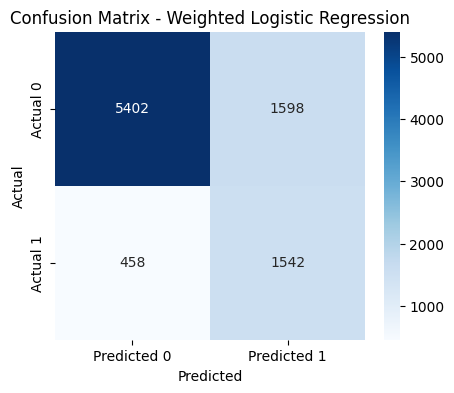

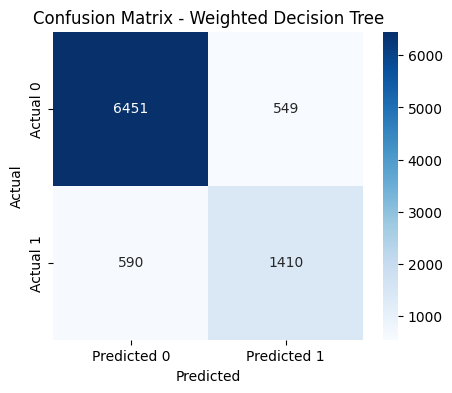

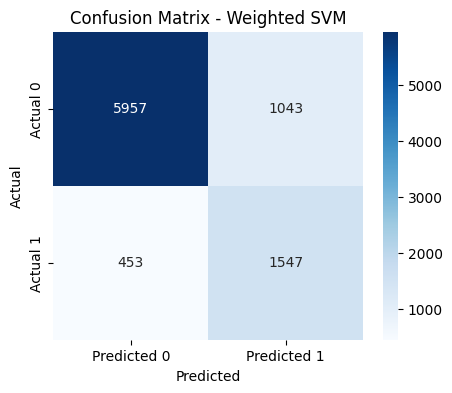

In [ ]:

# CONFUSION MATRICES
for name, (model, X_eval) in models.items():

    # Predict using the corresponding test dataset
    y_pred = model.predict(X_eval)

    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(5, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Predicted 0", "Predicted 1"],
        yticklabels=["Actual 0", "Actual 1"]
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()